# Week 11 — Web Analytics
### From raw clicks to sessions, funnels and trustworthy experiments
**SENG 42293 Big Data Analytics · LO3, LO4**

Every click on a website is an event. Web analytics turns an **event stream** into decisions: *where do visitors drop out? did the new page design actually help?*

**In this notebook:** event logs · **sessionisation** (30-minute rule) · key metrics · the **conversion funnel** · segments (device, channel) · **A/B testing** (z-test, confidence interval, power) · the **peeking problem** · sessionisation on **Spark window functions**.

**Data:** `clickstream.csv`, about 44,000 events from 6,000 visitors of the travel site (page, device, channel, A/B `variant`).

> The clickstream is **synthetic**, generated with a built-in lift for variant B so that an experiment has something to find. Real effects are usually smaller and noisier.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

In [2]:
ev = pd.read_csv("data/clickstream.csv", parse_dates=["timestamp"]).sort_values(["user_id", "timestamp"]).reset_index(drop=True)
print(ev.shape, "| period:", ev.timestamp.min().date(), "to", ev.timestamp.max().date(), "| visitors:", ev.user_id.nunique())
display(ev.head(8))
print("variants per visitor (should be 1):", ev.groupby("user_id").variant.nunique().max())
RES["events"], RES["visitors"] = len(ev), int(ev.user_id.nunique())

(44276, 7) | period: 2025-01-01 to 2025-05-09 | visitors: 6000


,user_id,timestamp,page,hotel_id,device,channel,variant
0,U00001,2025-03-25 08:04:00,home,NaN,mobile,search,A
1,U00001,2025-03-25 08:05:41,search,NaN,mobile,search,A
2,U00001,2025-03-25 08:07:58,hotel_page,H-1019,mobile,search,A
3,U00001,2025-03-25 08:08:28,reviews_tab,H-1019,mobile,search,A
4,U00001,2025-04-13 08:04:00,home,NaN,mobile,search,A
5,U00001,2025-04-13 08:05:56,search,NaN,mobile,search,A
6,U00001,2025-04-13 08:06:35,hotel_page,H-1298,mobile,search,A
7,U00002,2025-01-18 16:26:00,home,NaN,tablet,search,B


variants per visitor (should be 1): 1


## 1. Sessionisation
The log has no "session" column: we **derive** one. Convention (used by Google Analytics): a new session starts when the gap since the visitor's previous event exceeds **30 minutes**.

Algorithm: sort by (user, time) → compute the gap to the previous event of the same user → flag `new_session` if gap > 30 min or first event → running sum of flags gives a session number.

In [3]:
GAP = pd.Timedelta(minutes=30)
ev["gap"] = ev.groupby("user_id").timestamp.diff()
ev["new_session"] = (ev.gap.isna() | (ev.gap > GAP)).astype(int)
ev["session"] = ev.groupby("user_id").new_session.cumsum()
ev["sid"] = ev.user_id + "-" + ev.session.astype(str)
S = ev.groupby("sid").agg(user_id=("user_id", "first"), start=("timestamp", "min"), end=("timestamp", "max"), events=("page", "size"),
                          variant=("variant", "first"), device=("device", "first"), channel=("channel", "first"),
                          converted=("page", lambda p: (p == "confirmation").any()))
S["minutes"] = (S.end - S.start).dt.total_seconds() / 60
print(f"sessions = {len(S):,} | sessions per visitor = {len(S) / ev.user_id.nunique():.2f} | median events/session = {S.events.median():.0f} | median duration = {S.minutes.median():.1f} min")
RES["sessions"] = len(S); RES["sess_per_visitor"] = round(len(S) / ev.user_id.nunique(), 3)
for g in [10, 30, 60]:
    ns = ((ev.gap.isna()) | (ev.gap > pd.Timedelta(minutes=g))).sum(); print(f"  gap threshold {g:>2} min -> {ns:,} sessions")
RES["gap_sensitivity"] = {str(g): int(((ev.gap.isna()) | (ev.gap > pd.Timedelta(minutes=g))).sum()) for g in [10, 30, 60]}

sessions = 10,084 | sessions per visitor = 1.68 | median events/session = 4 | median duration = 4.3 min
  gap threshold 10 min -> 10,084 sessions
  gap threshold 30 min -> 10,084 sessions
  gap threshold 60 min -> 10,084 sessions


The 30-minute figure is a **convention, not a law**. In this *synthetic* log the count is identical at 10, 30 and 60 minutes because the generator makes within-visit gaps short (minutes) and between-visit gaps long (hours), so no gap falls in between. **Real logs are not so tidy:** their session counts move with the threshold, so always state the rule you used.

## 2. Core metrics
* **Bounce rate** = share of sessions with a single event.
* **Conversion rate** = share of sessions reaching `confirmation`.
* **Pages per session**, **session duration**.

In [4]:
bounce = (S.events == 1).mean(); conv = S.converted.mean()
print(f"bounce rate = {bounce:.1%} | conversion (per session) = {conv:.2%} | pages/session = {S.events.mean():.2f}")
RES["metrics"] = {"bounce": round(float(bounce), 4), "conversion": round(float(conv), 4), "pages_per_session": round(float(S.events.mean()), 2)}
seg = pd.concat({d: S.groupby(d).agg(sessions=("events", "size"), bounce=("events", lambda e: (e == 1).mean()), conversion=("converted", "mean")) for d in ["device", "channel"]}); display(seg.round(4))
RES["segments"] = {f"{a}:{b}": {"sessions": int(r.sessions), "bounce": round(float(r.bounce), 4), "conversion": round(float(r.conversion), 4)} for (a, b), r in seg.iterrows()}

bounce rate = 14.7% | conversion (per session) = 12.49% | pages/session = 4.39


sessions  bounce  conversion
device  desktop      3806  0.1479      0.1445
        mobile       5575  0.1487      0.1114
        tablet        703  0.1294      0.1252
channel direct       2038  0.1472      0.1237
        email        1514  0.1565      0.1222
        search       4040  0.1453      0.1262
        social       2492  0.1441      0.1252

## 3. The conversion funnel
Count the **visitors** (not events) reaching each step in order, and the step-to-step drop. Large drops show where to invest.

,step,visitors,% of first step,step conversion
0,home,6000,1.000,NaN
1,search,5508,0.918,0.918
2,hotel_page,5508,0.918,1.000
3,booking_start,2172,0.362,0.394
4,payment,1436,0.239,0.661
5,confirmation,1170,0.195,0.815


largest relative drop: into 'booking_start' (only 39.4% of the previous step continue)


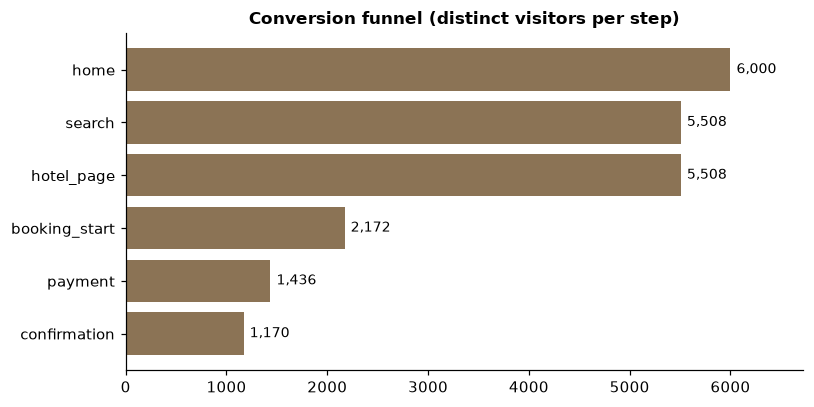

In [5]:
steps = ["home", "search", "hotel_page", "booking_start", "payment", "confirmation"]
reached = [ev.loc[ev.page == p, "user_id"].nunique() for p in steps]
F = pd.DataFrame({"step": steps, "visitors": reached}); F["% of first step"] = (F.visitors / F.visitors.iloc[0]).round(3); F["step conversion"] = (F.visitors / F.visitors.shift(1)).round(3); display(F)
RES["funnel"] = dict(zip(steps, map(int, reached)))
worst = F.iloc[1:].sort_values("step conversion").iloc[0]; print(f"largest relative drop: into '{worst.step}' (only {worst['step conversion']:.1%} of the previous step continue)")
RES["worst_step"] = [worst.step, float(worst["step conversion"])]
fig, ax = plt.subplots(figsize=(7.5, 3.8)); ax.barh(steps[::-1], reached[::-1], color=ACC)
for i, v in enumerate(reached[::-1]): ax.text(v + 60, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Conversion funnel (distinct visitors per step)"); ax.set_xlim(0, max(reached) * 1.12); save("w11_funnel")

Count `user_id` distinct, not rows: a visitor who refreshes the payment page five times is still **one** visitor at that step.

## 4. When do people visit?

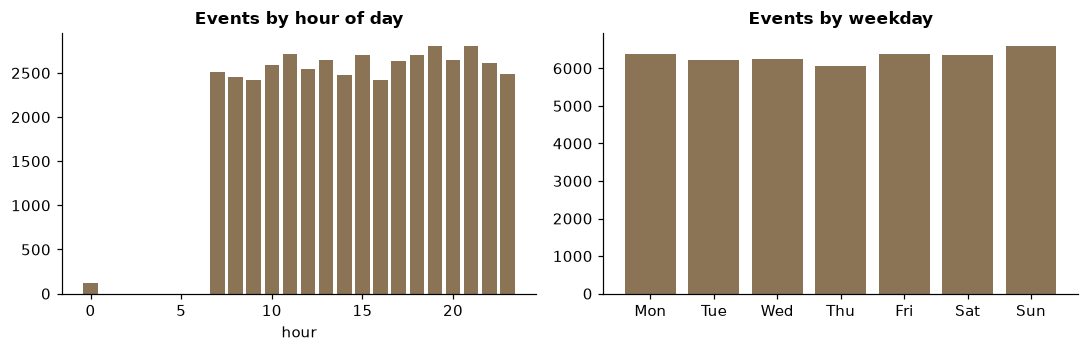

peak hour: 21 | busiest weekday: Sunday


In [6]:
ev["hour"] = ev.timestamp.dt.hour; ev["dow"] = ev.timestamp.dt.day_name()
hrs = ev.groupby("hour").size(); dows = ev.groupby("dow").size().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3)); ax[0].bar(hrs.index, hrs.values, color=ACC); ax[0].set_title("Events by hour of day"); ax[0].set_xlabel("hour")
ax[1].bar([d[:3] for d in dows.index], dows.values, color=ACC); ax[1].set_title("Events by weekday"); save("w11_time")
RES["peak_hour"] = int(hrs.idxmax()); RES["peak_day"] = dows.idxmax()
print("peak hour:", RES["peak_hour"], "| busiest weekday:", RES["peak_day"])

## 5. A/B test: did variant B really improve conversion?
Visitors were randomly assigned to **A** (control) or **B** (new design). Metric: **visitor-level conversion** (reached `confirmation`). With two proportions, use the **two-proportion z-test**:

**z = (p̂_B − p̂_A) / √( p̂(1−p̂)(1/n_A + 1/n_B) ),**  p̂ = pooled conversion rate.

Analyse by **visitor**, not session or event: the same person appearing in many sessions would otherwise be counted many times (unit-of-analysis error).

,sum,count,rate
variant,,,
A,547,3000,0.1823
B,623,3000,0.2077


A = 18.233%, B = 20.767% | absolute lift = +2.533% (relative +13.9%) | z = 2.48, p = 0.013
95% CI for the difference: [+0.529%, +4.537%]


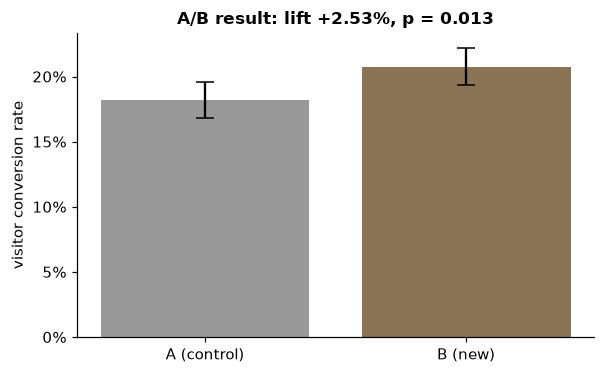

In [7]:
from scipy import stats
V = ev.groupby("user_id").agg(variant=("variant", "first"), conv=("page", lambda p: (p == "confirmation").any()))
g = V.groupby("variant").conv.agg(["sum", "count"]); g["rate"] = g["sum"] / g["count"]; display(g.round(4))
xa, na, xb, nb_ = g.loc["A", "sum"], g.loc["A", "count"], g.loc["B", "sum"], g.loc["B", "count"]; pa, pb = xa / na, xb / nb_
pp = (xa + xb) / (na + nb_); se = np.sqrt(pp * (1 - pp) * (1 / na + 1 / nb_)); z = (pb - pa) / se; pval = 2 * (1 - stats.norm.cdf(abs(z)))
se_u = np.sqrt(pa * (1 - pa) / na + pb * (1 - pb) / nb_); lo, hi = (pb - pa) - 1.96 * se_u, (pb - pa) + 1.96 * se_u
print(f"A = {pa:.3%}, B = {pb:.3%} | absolute lift = {pb - pa:+.3%} (relative {pb / pa - 1:+.1%}) | z = {z:.2f}, p = {pval:.2g}")
print(f"95% CI for the difference: [{lo:+.3%}, {hi:+.3%}]")
RES["ab"] = {"n_A": int(na), "n_B": int(nb_), "rate_A": round(float(pa), 4), "rate_B": round(float(pb), 4), "lift_abs": round(float(pb - pa), 4), "lift_rel": round(float(pb / pa - 1), 3),
             "z": round(float(z), 2), "p": float(pval), "ci": [round(float(lo), 4), round(float(hi), 4)]}
fig, ax = plt.subplots(figsize=(5.6, 3.5)); ax.bar(["A (control)", "B (new)"], [pa, pb], color=[GREY, ACC], yerr=[1.96 * np.sqrt(pa * (1 - pa) / na), 1.96 * np.sqrt(pb * (1 - pb) / nb_)], capsize=6)
ax.set_ylabel("visitor conversion rate"); ax.set_title(f"A/B result: lift {pb - pa:+.2%}, p = {pval:.2g}"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); save("w11_ab")

**Statistical significance is not business significance.** Read the *confidence interval*: it gives the plausible range of the true lift. A tiny but significant lift may not repay the engineering cost; a large but uncertain one may justify a longer test.

## 6. Power and sample size: plan the test *before* running it
How many visitors per group are needed to detect a given lift with 80% power at α = 0.05?

**n per group ≈ 2 · p̄(1−p̄) · (z_{α/2} + z_β)² / δ²**, where δ is the absolute difference to detect.

 detect lift (abs)  visitors per group
             0.005               94608
             0.010               23899
             0.020                6097
             0.030                2763
             0.050                1032


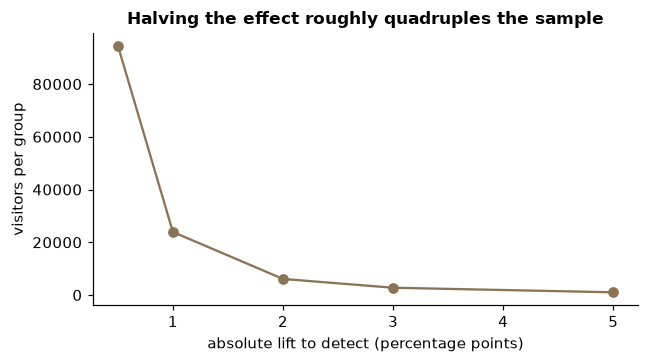

In [8]:
def n_needed(p0, delta, alpha=.05, power=.8):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power); pbar = p0 + delta / 2
    return int(np.ceil(2 * pbar * (1 - pbar) * (za + zb) ** 2 / delta ** 2))
deltas = np.array([.005, .01, .02, .03, .05]); ns = [n_needed(pa, d) for d in deltas]
print(pd.DataFrame({"detect lift (abs)": deltas, "visitors per group": ns}).to_string(index=False))
RES["power"] = {f"{d:.3f}": n for d, n in zip(deltas, ns)}; RES["observed_n_per_group"] = int(min(na, nb_))
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.plot(deltas * 100, ns, "o-", color=ACC); ax.set_xlabel("absolute lift to detect (percentage points)"); ax.set_ylabel("visitors per group"); ax.set_title("Halving the effect roughly quadruples the sample"); save("w11_power")

## 7. The peeking problem
If you check the p-value every day and **stop as soon as p < 0.05**, the false-positive rate is far above 5%. We prove it with an **A/A test**: both groups get the *same* design, so any "significant" result is a false alarm.

false-positive rate, test once at the end: 4.7%   |   stop at first 'significant' daily peek: 28.2%   (nominal 5%)


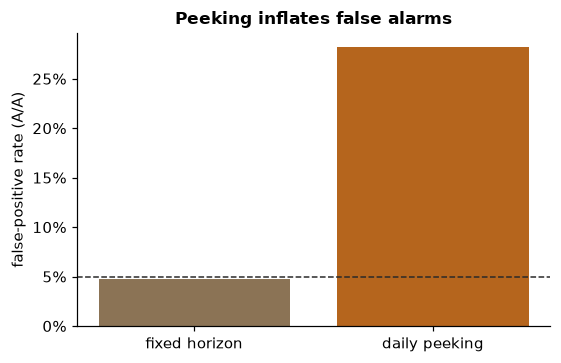

In [9]:
rng = np.random.default_rng(11); p_true, per_day, days, sims = pa, 200, 30, 1500
fixed_fp = peek_fp = 0
for _ in range(sims):
    a = rng.random((days, per_day)) < p_true; b = rng.random((days, per_day)) < p_true
    ca, cb = a.cumsum(0).sum(1) if False else np.cumsum(a.sum(1)), np.cumsum(b.sum(1)); n = per_day * np.arange(1, days + 1)
    pp_ = (ca + cb) / (2 * n); zz = (cb / n - ca / n) / np.sqrt(pp_ * (1 - pp_) * 2 / n + 1e-12); sig = np.abs(zz) > 1.96
    fixed_fp += sig[-1]; peek_fp += sig.any()
print(f"false-positive rate, test once at the end: {fixed_fp / sims:.1%}   |   stop at first 'significant' daily peek: {peek_fp / sims:.1%}   (nominal 5%)")
RES["peeking"] = {"fixed": round(fixed_fp / sims, 3), "peek": round(peek_fp / sims, 3), "sims": sims}
fig, ax = plt.subplots(figsize=(5.2, 3.4)); ax.bar(["fixed horizon", "daily peeking"], [fixed_fp / sims, peek_fp / sims], color=[ACC, "#b5651d"]); ax.axhline(.05, color=CH, ls="--", lw=1)
ax.set_ylabel("false-positive rate (A/A)"); ax.set_title("Peeking inflates false alarms"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); save("w11_peeking")

**Rule:** fix the sample size (or duration) *in advance* and analyse once, or use sequential methods designed for continuous monitoring.

## 8. Segments: does the lift hold for everyone?
A good result should be checked for consistency across devices. Beware: with many segments, some will look significant by chance (**multiple comparisons**).

In [10]:
dev = ev.groupby("user_id").device.agg(lambda s: s.mode().iat[0]); V["device"] = dev
rows = []
for d, sub in V.groupby("device"):
    ga = sub[sub.variant == "A"].conv; gb = sub[sub.variant == "B"].conv
    rows.append((d, len(ga), len(gb), ga.mean(), gb.mean(), gb.mean() - ga.mean()))
sg = pd.DataFrame(rows, columns=["device", "n_A", "n_B", "rate_A", "rate_B", "lift"]).round(4); display(sg)
RES["segment_lift"] = {r.device: {"rate_A": r.rate_A, "rate_B": r.rate_B, "lift": r.lift, "n": int(r.n_A + r.n_B)} for r in sg.itertuples()}

,device,n_A,n_B,rate_A,rate_B,lift
0,desktop,1142,1149,0.2137,0.2306,0.0170
1,mobile,1642,1654,0.1602,0.1923,0.0321
2,tablet,216,197,0.1852,0.2030,0.0179


## 9. Sessionisation at scale: Spark window functions
Pandas fails when the log no longer fits one machine. The same algorithm on Spark uses **`lag()` over a window partitioned by user** and a **running sum**. Only events of the *same user* must be co-located, so the shuffle is by `user_id`.

In [11]:
import sys; os.environ["PYSPARK_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F, Window
spark = SparkSession.builder.master("local[4]").config("spark.ui.enabled", "false").config("spark.sql.shuffle.partitions", "4").getOrCreate(); spark.sparkContext.setLogLevel("ERROR")
sdf = spark.read.csv("data/clickstream.csv", header=True).withColumn("ts", F.to_timestamp("timestamp"))
w = Window.partitionBy("user_id").orderBy("ts")
sdf = (sdf.withColumn("gap_s", F.col("ts").cast("long") - F.lag("ts").over(w).cast("long"))
          .withColumn("new", F.when(F.col("gap_s").isNull() | (F.col("gap_s") > 1800), 1).otherwise(0))
          .withColumn("session", F.sum("new").over(w.rowsBetween(Window.unboundedPreceding, Window.currentRow))))
n_sess = sdf.select("user_id", "session").distinct().count()
conv_sess = sdf.filter(F.col("page") == "confirmation").select("user_id", "session").distinct().count()
fun = (sdf.groupBy("page").agg(F.countDistinct("user_id").alias("visitors")).orderBy(F.desc("visitors")).collect())
print(f"Spark sessions = {n_sess:,} (pandas: {len(S):,}) | converting sessions = {conv_sess:,} (pandas: {int(S.converted.sum()):,})")
print("distinct visitors per page:", {r.page: r.visitors for r in fun})
RES["spark"] = {"sessions": int(n_sess), "match_pandas": bool(n_sess == len(S)), "converting_sessions": int(conv_sess)}
spark.stop()

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/10/13 09:29:10 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/13 09:29:10 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/13 09:29:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark sessions = 10,084 (pandas: 10,084) | converting sessions = 1,259 (pandas: 1,259)
distinct visitors per page: {'home': 6000, 'hotel_page': 5508, 'search': 5508, 'reviews_tab': 4057, 'booking_start': 2172, 'payment': 1436, 'confirmation': 1170}


Matching counts confirm the distributed version implements the same logic. Production systems run this as an incremental job over hourly partitions of Parquet, not over one CSV.

## 10. Pitfalls checklist
| Pitfall | Why it matters |
|---|---|
| Bots and crawlers | inflate traffic, depress conversion; filter by user-agent and behaviour |
| Wrong unit of analysis | analyse by randomisation unit (visitor), not by event |
| Peeking / stopping early | false positives (section 7) |
| Novelty effect | a new design wins early because it is new; run for full weekly cycles |
| Sample-ratio mismatch | if a 50/50 split is 55/45, assignment is broken: check before trusting results |
| Privacy | cookies and IDs are personal data: consent, minimisation, retention limits |

## 11. Exercises
1. Change the session gap to 1 minute and to 24 hours. At what threshold does the session count start to change, and what does that tell you about this log?
2. Compute the funnel separately for `mobile` and `desktop`. Where do they differ most?
3. How many visitors per group would you need to detect a 0.5-percentage-point lift? How long is that at today's traffic?
4. Check the sample-ratio: is the A/B split consistent with 50/50? (Hint: a chi-square test with one degree of freedom.)
5. Run the peeking simulation with a Bonferroni-style stricter threshold (|z| > 2.8). What happens to the false-positive rate and to power?

In [12]:
json.dump(RES, open("results/w11.json", "w"), indent=1); print(json.dumps(RES)[:600])

{"events": 44276, "visitors": 6000, "sessions": 10084, "sess_per_visitor": 1.681, "gap_sensitivity": {"10": 10084, "30": 10084, "60": 10084}, "metrics": {"bounce": 0.1471, "conversion": 0.1249, "pages_per_session": 4.39}, "segments": {"device:desktop": {"sessions": 3806, "bounce": 0.1479, "conversion": 0.1445}, "device:mobile": {"sessions": 5575, "bounce": 0.1487, "conversion": 0.1114}, "device:tablet": {"sessions": 703, "bounce": 0.1294, "conversion": 0.1252}, "channel:direct": {"sessions": 2038, "bounce": 0.1472, "conversion": 0.1237}, "channel:email": {"sessions": 1514, "bounce": 0.1565, "c
